# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 1: Phân lớp dữ liệu Adult Income (Mục 2 trang 15 - 23)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu 1: Nhập dữ liệu đầu vào và cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [2]:
# Câu 1: Nhập dữ liệu đầu vào và thống kê số lượng mẫu
train_path = get_data_path("adult.data.csv")
test_path = get_data_path("adult.test.csv")

train_data = pd.read_csv(train_path, skipinitialspace=True)
test_data = pd.read_csv(test_path, skipinitialspace=True)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Số lượng dữ liệu huấn luyện: {len(train_data)}")
print(f"Số lượng dữ liệu kiểm thử: {len(test_data)}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Số lượng dữ liệu huấn luyện: 32561
Số lượng dữ liệu kiểm thử: 16281


### Câu 2: Tiến hành tiền xử lý dữ liệu
- Xóa các dòng có chứa dữ liệu trống (ký hiệu bằng '?').
- Xóa cột final weight 'fnlwgt' trong dữ liệu huấn luyện.
- Nối dữ liệu huấn luyện và kiểm thử lại với nhau.

In [3]:
# Câu 2: Tiền xử lý dữ liệu
train_clean = train_data.replace('?', np.nan).dropna()
test_clean = test_data.replace('?', np.nan).dropna()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Number of training data: {len(train_clean)}")
print(f"Number of test data: {len(test_clean)}")

# Xóa cột final weight 'fnlwgt' trong dữ liệu huấn luyện
if 'fnlwgt' in train_clean.columns:
    train_clean = train_clean.drop(columns=['fnlwgt'])

# Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train_clean, test_clean], ignore_index=True)
print("\nThông tin khối dữ liệu sau khi nối:")
data.info()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Number of training data: 30162
Number of test data: 15060

Thông tin khối dữ liệu sau khi nối:
<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income          45222 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.8 MB


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
- Tính ma trận hệ số tương quan Pearson giữa các thuộc tính số.
- Trực quan hóa bằng biểu đồ Heatmap của Seaborn.

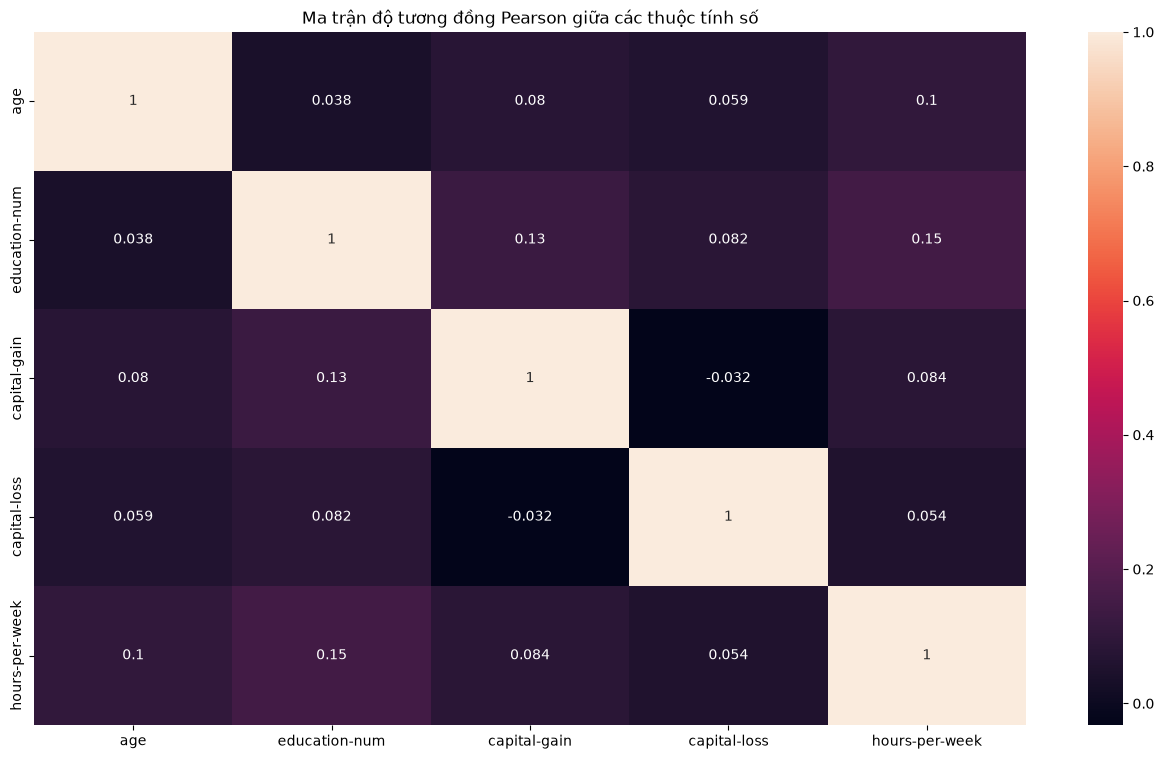

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Nhận xét: Các hệ số tương quan giữa các cặp thuộc tính số đều nhỏ (< 0.2). Không có thuộc tính nào có độ tương đồng quá cao cần loại bỏ.


In [4]:
# Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
plt.figure(figsize=(16, 9))
numeric_data = data.select_dtypes(include=['int64'])
corr_matrix = numeric_data.corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, cmap='rocket')
plt.title("Ma trận độ tương đồng Pearson giữa các thuộc tính số")
plt.show()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print("Nhận xét: Các hệ số tương quan giữa các cặp thuộc tính số đều nhỏ (< 0.2). Không có thuộc tính nào có độ tương đồng quá cao cần loại bỏ.")

### Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
- Phần 1 (features): Chứa các thuộc tính dự đoán độc lập (loại bỏ cột 'income').
- Phần 2 (labels): Chứa thuộc tính quyết định ('income').

In [5]:
# Câu 4: Tách các cột dữ liệu thành hai phần
features = data.drop('income', axis=1)
labels = data['income']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập thuộc tính dự đoán (features): {features.shape}")
print(f"Kích thước thuộc tính quyết định (labels): {labels.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập thuộc tính dự đoán (features): (45222, 13)
Kích thước thuộc tính quyết định (labels): (45222,)


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
- Xác định các cột phân loại (dạng object/chuỗi).
- Áp dụng phương thức pd.get_dummies() để tạo vector đặc trưng one-hot.

In [6]:
# Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
categorical_cols = features.select_dtypes(exclude=['int64']).columns
print("Các thuộc tính phân loại được mã hóa one-hot:")
print(list(categorical_cols))

features_onehot = pd.get_dummies(features, columns=categorical_cols, dtype=int)

print()
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước dữ liệu đặc trưng sau khi chuyển đổi: {features_onehot.shape}")
display(features_onehot.head())

Các thuộc tính phân loại được mã hóa one-hot:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước dữ liệu đặc trưng sau khi chuyển đổi: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử như ban đầu
- Tập huấn luyện: 30,162 dòng đầu tiên.
- Tập kiểm thử: 15,060 dòng còn lại.

In [7]:
# Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử như ban đầu
n_train = len(train_clean)

X_train = features_onehot.iloc[:n_train]
X_test = features_onehot.iloc[n_train:]
y_train = labels.iloc[:n_train]
y_test = labels.iloc[n_train:]

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước X_test: {X_test.shape}, y_test: {y_test.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước X_train: (30162, 103), y_train: (30162,)
Kích thước X_test: (15060, 103), y_test: (15060,)


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng mô hình DecisionTreeClassifier với tiêu chí entropy (Information Gain).
- Đánh giá độ chính xác và ma trận nhầm lẫn (Confusion Matrix).
- Biểu diễn cấu trúc cây quyết định.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
ID3 Decision Tree Accuracy: 0.8175

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



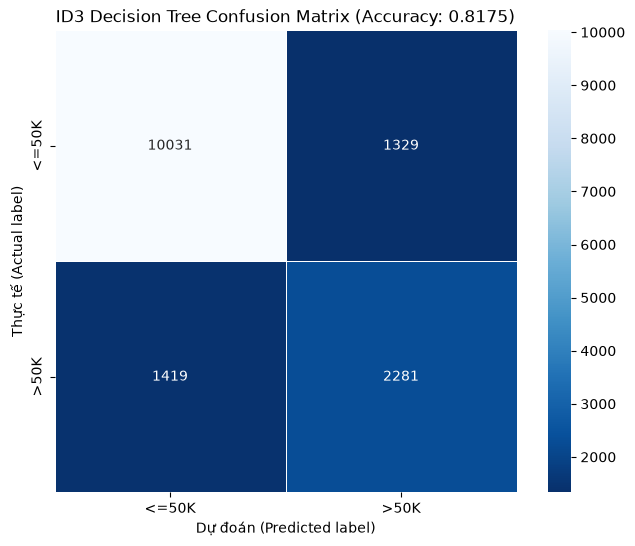

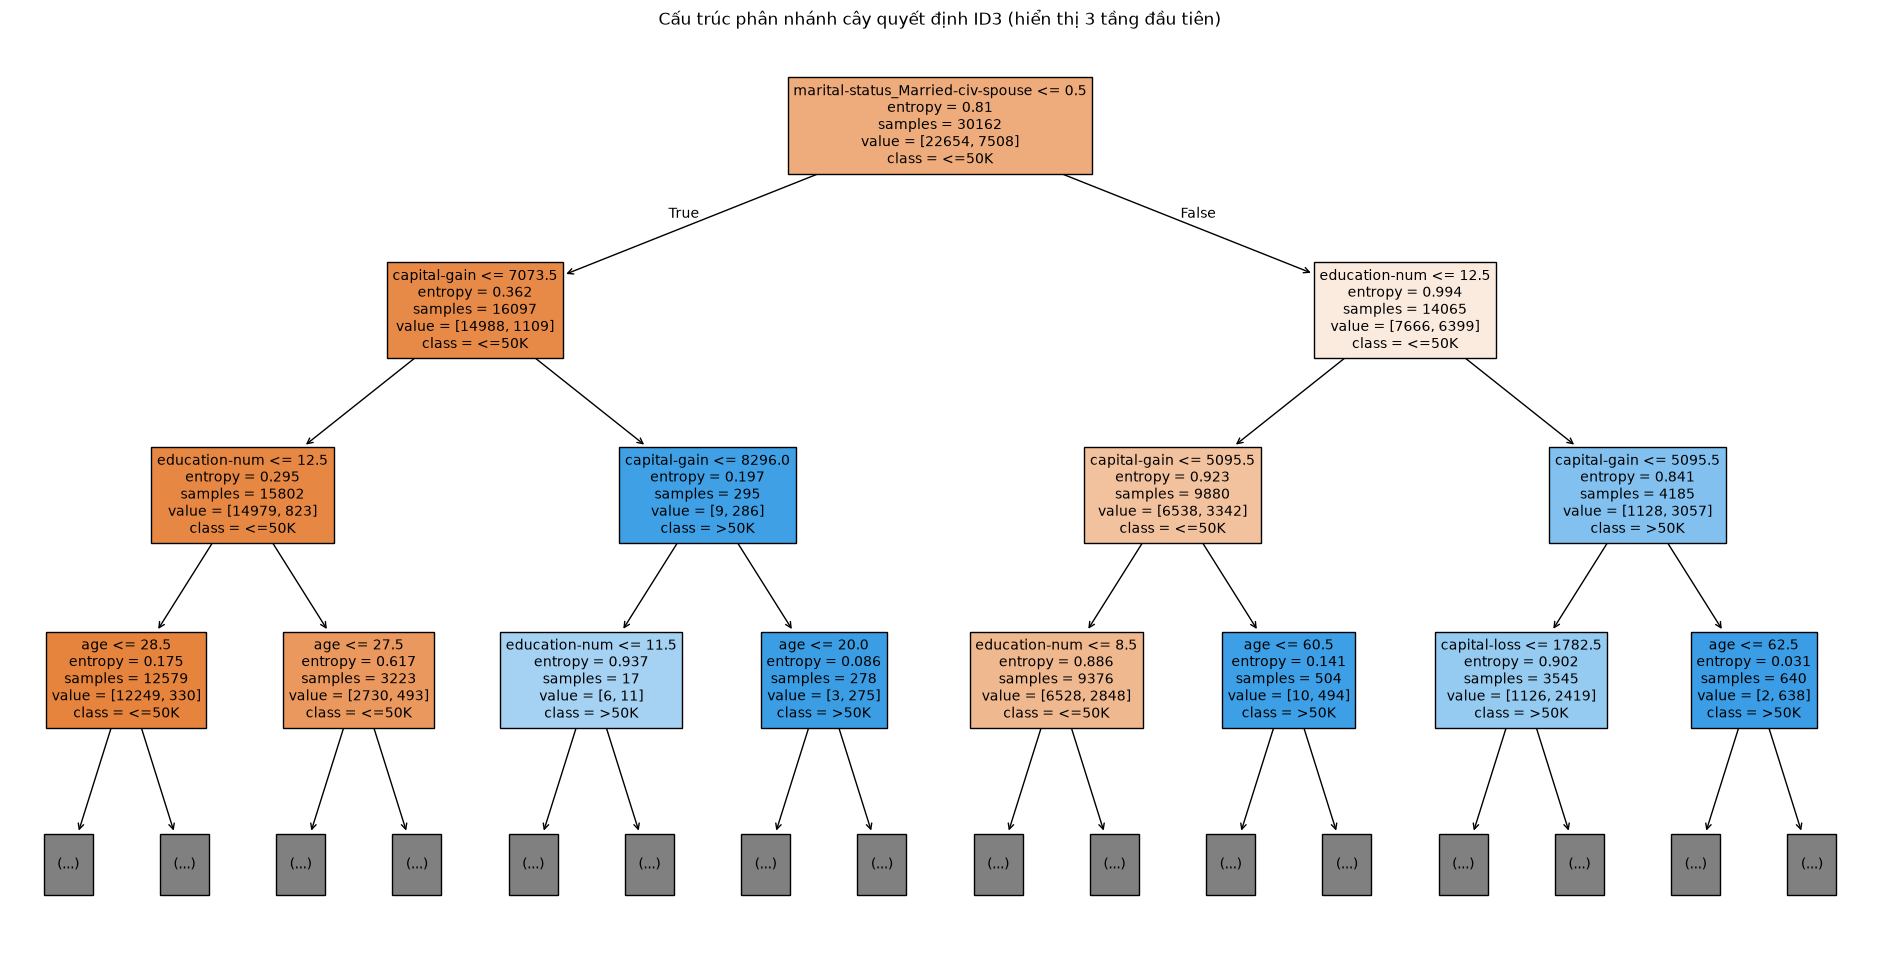

In [8]:
# Câu 7: Xây dựng cây ID3
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"ID3 Decision Tree Accuracy: {id3_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred))

# Ma trận nhầm lẫn dạng Heatmap
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel('Thực tế (Actual label)')
plt.xlabel('Dự đoán (Predicted label)')
plt.title(f'ID3 Decision Tree Confusion Matrix (Accuracy: {id3_score:.4f})')
plt.show()

# Biểu diễn cây quyết định (hiển thị 3 tầng đầu để quan sát rõ điều kiện phân nhánh)
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=X_train.columns.tolist(),
               class_names=list(map(str, clf_id3.classes_)), filled=True, fontsize=10)
plt.title("Cấu trúc phân nhánh cây quyết định ID3 (hiển thị 3 tầng đầu tiên)")
plt.show()